# Advanced Knowledge Distillation Techniques

This notebook covers advanced methods and optimizations for knowledge distillation, building on the basics from previous notebooks. We'll explore multi-teacher distillation, self-distillation, and more.

## Setup

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import numpy as np
import matplotlib.pyplot as plt

torch.manual_seed(42)
np.random.seed(42)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {device}")

Device: cpu


## Technique 1: Multi-Teacher Distillation

Instead of learning from one teacher, the student learns from multiple teachers with different strengths. This creates an ensemble effect.

In [2]:
def multi_teacher_distillation_loss(student_logits, teacher_logits_list, labels, temperature=3.0, alpha=0.7, teacher_weights=None):
    """
    distill from several teachers by matching a weighted average of their softened outputs
    
    args:
        student_logits: raw student outputs
        teacher_logits_list: raw outputs from each teacher
        labels: ground truth class indices
        temperature: softening parameter
        alpha: weight on the distillation term, 1 - alpha goes to the label term
        teacher_weights: how much each teacher is trusted, should sum to 1 (default: equal weights)
    """
    num_teachers = len(teacher_logits_list)
    
    if teacher_weights is None:
        teacher_weights = [1.0 / num_teachers] * num_teachers
    
    # averaging probabilities rather than logits keeps the ensemble target a proper distribution
    ensemble_soft = torch.zeros_like(
        F.softmax(teacher_logits_list[0] / temperature, dim=-1))
    
    for teacher_logits, weight in zip(teacher_logits_list, teacher_weights):
        soft_teacher = F.softmax(teacher_logits / temperature, dim=-1)
        ensemble_soft += weight * soft_teacher
    
    soft_student = F.log_softmax(student_logits / temperature, dim=-1)
    
    distill_loss = F.kl_div(
        soft_student, ensemble_soft, reduction='batchmean') * (temperature ** 2)
    student_loss = F.cross_entropy(student_logits, labels)
    
    return alpha * distill_loss + (1 - alpha) * student_loss

# smoke test with untrained teachers, the loss value itself means nothing
class SimpleModel(nn.Module):
    def __init__(self, input_size=784, hidden_size=256, num_classes=10):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_size, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, num_classes))
    
    def forward(self, x):
        return self.net(x)

teacher1 = SimpleModel(hidden_size=512).to(device)
teacher2 = SimpleModel(hidden_size=384).to(device)
teacher3 = SimpleModel(hidden_size=256).to(device)
student = SimpleModel(hidden_size=128).to(device)

dummy_input = torch.randn(4, 784).to(device)
dummy_labels = torch.randint(0, 10, (4,)).to(device)

with torch.no_grad():
    t1_out = teacher1(dummy_input)
    t2_out = teacher2(dummy_input)
    t3_out = teacher3(dummy_input)

s_out = student(dummy_input)

loss = multi_teacher_distillation_loss(
    s_out, [t1_out, t2_out, t3_out], dummy_labels,
    teacher_weights=[0.5, 0.3, 0.2] ) # unequal weights trust the first teacher most

print(f"Multi-teacher distillation loss: {loss.item():.4f}")
print("\nThis combines knowledge from 3 teachers with weights [0.5, 0.3, 0.2]")

Multi-teacher distillation loss: 0.7390

This combines knowledge from 3 teachers with weights [0.5, 0.3, 0.2]


## Technique 2: Progressive Distillation

Gradually change temperature and alpha during training - start easy, get harder.

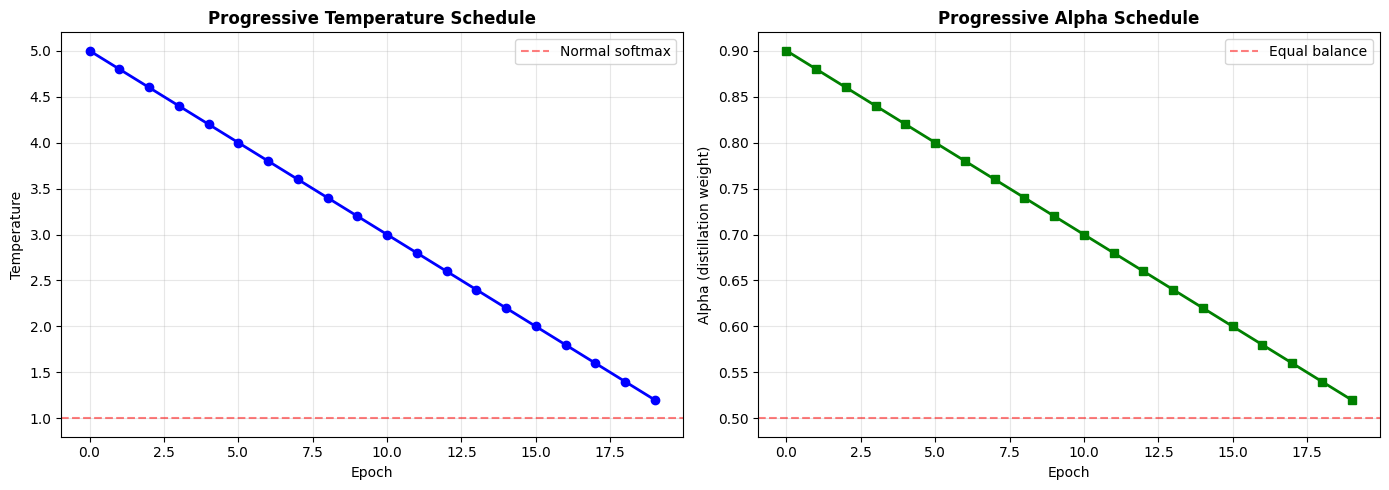

Early training: High temperature (soft, easy) + High alpha (rely on teacher)
Late training:  Low temperature (sharp, hard) + Low alpha (rely on labels)


In [3]:
# anneal from soft to sharp targets, note progress peaks at (num_epochs - 1) / num_epochs,
# so end_temp is never quite reached
def progressive_temperature_schedule(epoch, num_epochs, start_temp=5.0, end_temp=1.0):
    progress = epoch / num_epochs
    return start_temp * (1 - progress) + end_temp * progress


# shift weight from the teacher toward the true labels as training goes on
def progressive_alpha_schedule(epoch, num_epochs, start_alpha=0.9, end_alpha=0.5):
    progress = epoch / num_epochs
    return start_alpha * (1 - progress) + end_alpha * progress

epochs = np.arange(0, 20)
temps = [progressive_temperature_schedule(e, 20) for e in epochs]
alphas = [progressive_alpha_schedule(e, 20) for e in epochs]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(epochs, temps, marker='o', linewidth=2, color='blue')
axes[0].set_title('Progressive Temperature Schedule', fontweight='bold', fontsize=12)
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Temperature')
axes[0].grid(True, alpha=0.3)
axes[0].axhline(y=1.0, color='r', linestyle='--', alpha=0.5, label='Normal softmax')
axes[0].legend()

axes[1].plot(epochs, alphas, marker='s', linewidth=2, color='green')
axes[1].set_title('Progressive Alpha Schedule', fontweight='bold', fontsize=12)
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Alpha (distillation weight)')
axes[1].grid(True, alpha=0.3)
axes[1].axhline(y=0.5, color='r', linestyle='--', alpha=0.5, label='Equal balance')
axes[1].legend()

plt.tight_layout()
plt.show()

print("Early training: High temperature (soft, easy) + High alpha (rely on teacher)")
print("Late training:  Low temperature (sharp, hard) + Low alpha (rely on labels)")

### Progressive Distillation Training Loop

In [4]:

# train with progressive temperature and alpha schedules
def train_progressive_distillation(student, teacher, train_loader, num_epochs=15):
    optimizer = optim.Adam(student.parameters(), lr=0.001)
    teacher.eval()
    
    temp_history = []
    alpha_history = []
    loss_history = []
    
    print("Progressive Distillation Training:")
    
    for epoch in range(num_epochs):
        temperature = progressive_temperature_schedule(epoch, num_epochs)
        alpha = progressive_alpha_schedule(epoch, num_epochs)
        
        temp_history.append(temperature)
        alpha_history.append(alpha)
        
        student.train()
        epoch_loss = 0
        
        for batch_X, batch_y in train_loader:
            batch_X, batch_y = batch_X.to(device), batch_y.to(device)
            
            optimizer.zero_grad()
            
            with torch.no_grad():
                teacher_logits = teacher(batch_X)
            
            student_logits = student(batch_X)
            
            soft_teacher = F.softmax(teacher_logits / temperature, dim=-1)
            soft_student = F.log_softmax(student_logits / temperature, dim=-1)
            
            distill_loss = F.kl_div(soft_student, soft_teacher, reduction='batchmean') * (temperature ** 2)
            student_loss = F.cross_entropy(student_logits, batch_y)
            
            total_loss = alpha * distill_loss + (1 - alpha) * student_loss
            
            total_loss.backward()
            optimizer.step()
            
            epoch_loss += total_loss.item()
        
        avg_loss = epoch_loss / len(train_loader)
        loss_history.append(avg_loss)
        
        if (epoch + 1) % 3 == 0:
            print(f"Epoch {epoch+1:2d} | T={temperature:.2f} | α={alpha:.2f} | Loss={avg_loss:.4f}")
    
    return loss_history, temp_history, alpha_history

# random labels again: this shows the mechanics, not a real accuracy gain
train_X = torch.randn(1000, 784)
train_y = torch.randint(0, 10, (1000,))
train_loader = DataLoader(TensorDataset(train_X, train_y), batch_size=64, shuffle=True)

# the teacher has to be trained before it can teach
print("Pre-training teacher")
teacher = SimpleModel(hidden_size=256).to(device)
optimizer = optim.Adam(teacher.parameters(), lr=0.001)
teacher.train()
for _ in range(10):
    for batch_X, batch_y in train_loader:
        batch_X, batch_y = batch_X.to(device), batch_y.to(device)
        optimizer.zero_grad()
        outputs = teacher(batch_X)
        loss = F.cross_entropy(outputs, batch_y)
        loss.backward()
        optimizer.step()
print("Teacher training complete\n")

student = SimpleModel(hidden_size=128).to(device)
losses, temps, alphas = train_progressive_distillation(student, teacher, train_loader)

Pre-training teacher
Teacher training complete

Progressive Distillation Training:
Epoch  3 | T=4.47 | α=0.85 | Loss=2.3080
Epoch  6 | T=3.67 | α=0.77 | Loss=0.7054
Epoch  9 | T=2.87 | α=0.69 | Loss=0.1101
Epoch 12 | T=2.07 | α=0.61 | Loss=0.0327
Epoch 15 | T=1.27 | α=0.53 | Loss=0.0158


## Technique 3: Feature-Based Distillation

Match intermediate layer representations, not just final outputs.

In [5]:
class FeatureTeacher(nn.Module):
    """teacher that can also return its hidden layer activations"""
    def __init__(self, input_size=784, num_classes=10):
        super().__init__()
        self.layer1 = nn.Sequential(nn.Linear(input_size, 512), nn.ReLU())
        self.layer2 = nn.Sequential(nn.Linear(512, 256), nn.ReLU())
        self.layer3 = nn.Linear(256, num_classes)
    
    def forward(self, x, return_features=False):
        feat1 = self.layer1(x)
        feat2 = self.layer2(feat1)
        output = self.layer3(feat2)
        
        if return_features:
            return output, [feat1, feat2]
        return output

# student that can also return its hidden activations, projected to the teacher's widths
class FeatureStudent(nn.Module):
    
    def __init__(self, input_size=784, num_classes=10):
        super().__init__()
        self.layer1 = nn.Sequential(nn.Linear(input_size, 256), nn.ReLU())
        self.layer2 = nn.Sequential(nn.Linear(256, 128), nn.ReLU())
        self.layer3 = nn.Linear(128, num_classes)
        
        # learned projections let mse compare features of different widths, as in fitnets hints
        self.proj1 = nn.Linear(256, 512)
        self.proj2 = nn.Linear(128, 256)
    
    def forward(self, x, return_features=False):
        feat1 = self.layer1(x)
        feat2 = self.layer2(feat1)
        output = self.layer3(feat2)
        
        if return_features:
            proj_feat1 = self.proj1(feat1)
            proj_feat2 = self.proj2(feat2)
            return output, [proj_feat1, proj_feat2]
        return output

def feature_distillation_loss(student_outputs, student_features,teacher_outputs, teacher_features, labels, temperature=3.0, alpha=0.5, beta=0.3):
    """
    output distillation plus feature matching on hidden layers
    
    args:
        alpha: weight on output distillation
        beta: weight on feature matching
        1 - alpha - beta goes to the label term
    """
    # output term: the usual softened kl, times t^2
    soft_teacher = F.softmax(teacher_outputs / temperature, dim=-1)
    soft_student = F.log_softmax(student_outputs / temperature, dim=-1)
    output_loss = F.kl_div(soft_student, soft_teacher, reduction='batchmean') * (temperature ** 2)
    
    # feature term: mse between projected student features and teacher features
    feature_loss = 0
    for s_feat, t_feat in zip(student_features, teacher_features):
        feature_loss += F.mse_loss(s_feat, t_feat)
    feature_loss /= len(student_features)  # average over layers
    
    student_loss = F.cross_entropy(student_outputs, labels)
    
    total_loss = alpha * output_loss + beta * feature_loss + (1 - alpha - beta) * student_loss
    
    return total_loss, output_loss, feature_loss, student_loss

# smoke test, both models untrained
feat_teacher = FeatureTeacher().to(device)
feat_student = FeatureStudent().to(device)

dummy_input = torch.randn(8, 784).to(device)
dummy_labels = torch.randint(0, 10, (8,)).to(device)

t_out, t_feats = feat_teacher(dummy_input, return_features=True)
s_out, s_feats = feat_student(dummy_input, return_features=True)

total, out_loss, feat_loss, stud_loss = feature_distillation_loss(s_out, s_feats, t_out, t_feats, dummy_labels)

print("Feature-Based Distillation Loss Breakdown:")
print(f"Output Distillation Loss:{out_loss.item():.4f} (weight: 0.5)")
print(f"Feature Matching Loss:{feat_loss.item():.4f} (weight: 0.3)")
print(f"Student CE Loss:{stud_loss.item():.4f} (weight: 0.2)")
print(f"Total Loss:{total.item():.4f}")
print(f"\nNumber of feature layers matched: {len(s_feats)}")

Feature-Based Distillation Loss Breakdown:
Output Distillation Loss:0.0057 (weight: 0.5)
Feature Matching Loss:0.1295 (weight: 0.3)
Student CE Loss:2.3102 (weight: 0.2)
Total Loss:0.5037

Number of feature layers matched: 2


## Technique 4: Self-Distillation

The model learns from its own previous predictions - no separate teacher needed!

Self-Distillation Training:
Epoch  2 | Loss: 1.8582 | Stored predictions: 32
Epoch  4 | Loss: 1.1145 | Stored predictions: 64
Epoch  6 | Loss: 0.4583 | Stored predictions: 96
Epoch  8 | Loss: 0.1677 | Stored predictions: 128
Epoch 10 | Loss: 0.0781 | Stored predictions: 160


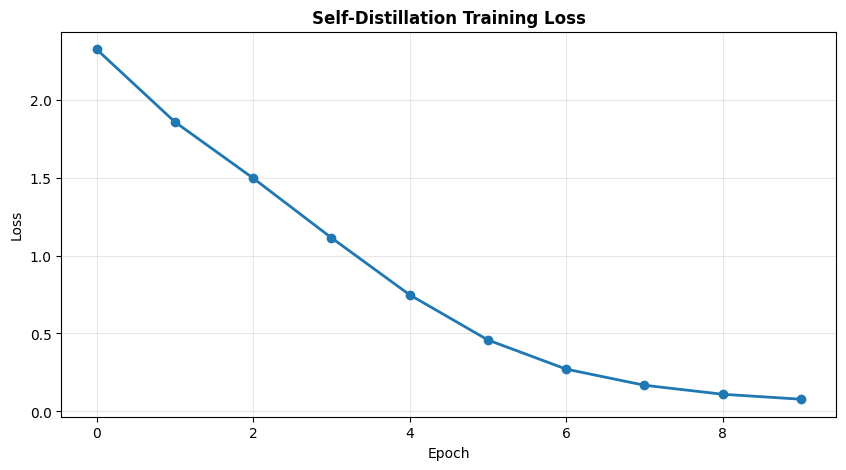


The model improves by learning from its own past predictions!


In [6]:
# self-distillation: the model's own logits from the previous epoch are meant to act as the teacher
def self_distillation_epoch(model, train_loader, previous_predictions, optimizer, epoch, temperature=3.0):
    model.train()
    epoch_loss = 0
    
    for batch_idx, (batch_X, batch_y) in enumerate(train_loader):
        batch_X, batch_y = batch_X.to(device), batch_y.to(device)
        
        optimizer.zero_grad()
        
        current_logits = model(batch_X)
        
        # note: the key contains the current epoch, so it never matches a key stored last epoch and
        # the distillation branch below never runs, with shuffling on the batches would not line up anyway
        batch_id = f"epoch_{epoch}_batch_{batch_idx}"
        
        if batch_id in previous_predictions:
            teacher_logits = previous_predictions[batch_id].to(device)
            
            soft_teacher = F.softmax(teacher_logits / temperature, dim=-1)
            soft_student = F.log_softmax(current_logits / temperature, dim=-1)
            
            distill_loss = F.kl_div(soft_student, soft_teacher, reduction='batchmean') * (temperature ** 2)
            student_loss = F.cross_entropy(current_logits, batch_y)
            
            loss = 0.7 * distill_loss + 0.3 * student_loss
        else:
            loss = F.cross_entropy(current_logits, batch_y)
        
        loss.backward()
        optimizer.step()
        
        epoch_loss += loss.item()
        
        # stored as the teacher signal for the next epoch
        with torch.no_grad():
            previous_predictions[batch_id] = current_logits.cpu().clone()
    
    return epoch_loss / len(train_loader)

print("Self-Distillation Training:")

model = SimpleModel(hidden_size=128).to(device)
optimizer = optim.Adam(model.parameters(), lr=0.001)
previous_preds = {}

losses = []
for epoch in range(10):
    loss = self_distillation_epoch(model, train_loader, previous_preds, optimizer, epoch)
    losses.append(loss)
    
    if (epoch + 1) % 2 == 0:
        print(f"Epoch {epoch+1:2d} | Loss: {loss:.4f} | "
              f"Stored predictions: {len(previous_preds)}")

plt.figure(figsize=(10, 5))
plt.plot(losses, marker='o', linewidth=2)
plt.title('Self-Distillation Training Loss', fontweight='bold', fontsize=12)
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid(True, alpha=0.3)
plt.show()

print("\nThe model improves by learning from its own past predictions!")

## Practical Optimization Tips for Large Models

When working with LLMs and large models:

In [7]:
# gradient accumulation: the effective batch is accumulation_steps times larger, at the memory cost of one
def train_with_gradient_accumulation(model, teacher, train_loader, accumulation_steps=4):
    """
    accumulate gradients over several batches before each optimizer step,
    useful when gpu memory is limited
    """
    optimizer = optim.Adam(model.parameters(), lr=0.001)
    teacher.eval()
    model.train()
    
    print(f"Training with gradient accumulation ({accumulation_steps} steps)")
    print("This simulates a {accumulation_steps}x larger batch size\n")
    
    optimizer.zero_grad()
    for i, (batch_X, batch_y) in enumerate(train_loader):
        batch_X, batch_y = batch_X.to(device), batch_y.to(device)
        
        with torch.no_grad():
            teacher_logits = teacher(batch_X)
        
        student_logits = model(batch_X)
        
        # soft term only, with no label term and no t^2 factor
        soft_teacher = F.softmax(teacher_logits / 3.0, dim=-1)
        soft_student = F.log_softmax(student_logits / 3.0, dim=-1)
        loss = F.kl_div(soft_student, soft_teacher, reduction='batchmean')
        
        # divide so the summed gradients equal the mean over the accumulated batches
        loss = loss / accumulation_steps
        loss.backward()
        
        if (i + 1) % accumulation_steps == 0:
            optimizer.step()
            optimizer.zero_grad()
            
        if i >= 20:  # demo cap, never reached here: the 1000 sample loader has only 16 batches
            break
    
    return model

print("Gradient Accumulation Example:")
model = SimpleModel().to(device)
model = train_with_gradient_accumulation(model, teacher, train_loader)
print("Training complete with reduced memory usage!\n")

Gradient Accumulation Example:
Training with gradient accumulation (4 steps)
This simulates a {accumulation_steps}x larger batch size

Training complete with reduced memory usage!



In [8]:
# selective distillation: only positions that matter (answer tokens, not padding) contribute
def selective_distillation_loss(student_logits, teacher_logits, mask):
    """
    distillation loss averaged over the positions the mask keeps,
    for llms: answer tokens count, padding does not
    
    args:
        mask: binary mask (1 = keep, 0 = ignore)
    """
    soft_teacher = F.softmax(teacher_logits / 3.0, dim=-1)
    soft_student = F.log_softmax(student_logits / 3.0, dim=-1)
    
    loss = F.kl_div(soft_student, soft_teacher, reduction='none')
    
    # broadcast the per position mask over the vocabulary axis
    if mask.dim() < loss.dim():
        mask = mask.unsqueeze(-1)
    
    # summed over the vocabulary and divided by kept positions: a mean per token kl, without t^2
    masked_loss = (loss * mask).sum() / mask.sum()
    
    return masked_loss

# random logits, the first three positions play the role of padding
batch_size, seq_len, vocab_size = 4, 10, 100

dummy_student = torch.randn(batch_size, seq_len, vocab_size)
dummy_teacher = torch.randn(batch_size, seq_len, vocab_size)

# mask: 1 for tokens to distill, 0 for padding
mask = torch.ones(batch_size, seq_len)
mask[:, :3] = 0

full_loss = F.kl_div(F.log_softmax(dummy_student / 3.0, dim=-1),F.softmax(dummy_teacher / 3.0, dim=-1),reduction='batchmean')

selective_loss = selective_distillation_loss(dummy_student, dummy_teacher, mask)

print("Selective Distillation:")
print(f"Full distillation loss:{full_loss.item():.4f}")
print(f"Selective distillation loss: {selective_loss.item():.4f}")
print(f"\nMask pattern: {mask[0].numpy()}")
print("Only computing loss on positions marked with 1")

Selective Distillation:
Full distillation loss:1.0996
Selective distillation loss: 0.1094

Mask pattern: [0. 0. 0. 1. 1. 1. 1. 1. 1. 1.]
Only computing loss on positions marked with 1


## Choosing the Right Technique

Here's a decision guide:

In [9]:
import pandas as pd

decision_guide = {
    'Scenario': [
        'Have one good teacher',
        'Have multiple teachers',
        'No teacher available',
        'Training is unstable',
        'Need fine-grained transfer',
        'Limited GPU memory',
        'Working with sequences/LLMs',
        'Teacher very large'
    ],
    'Recommended Technique': [
        'Standard distillation',
        'Multi-teacher distillation',
        'Self-distillation',
        'Progressive distillation',
        'Feature-based distillation',
        'Gradient accumulation',
        'Selective distillation',
        'Progressive + mixed precision'
    ],
    'Key Benefit': [
        'Simple and effective',
        'Better generalization',
        'No pre-trained model needed',
        'Smoother learning path',
        'Learns representations',
        'Reduces memory usage',
        'Focuses on important parts',
        'Handles very large models'
    ]
}

df = pd.DataFrame(decision_guide)
print("Knowledge Distillation Technique Selection Guide:")
print(df.to_string(index=False))
print("\n")

Knowledge Distillation Technique Selection Guide:
                   Scenario         Recommended Technique                 Key Benefit
      Have one good teacher         Standard distillation        Simple and effective
     Have multiple teachers    Multi-teacher distillation       Better generalization
       No teacher available             Self-distillation No pre-trained model needed
       Training is unstable      Progressive distillation      Smoother learning path
 Need fine-grained transfer    Feature-based distillation      Learns representations
         Limited GPU memory         Gradient accumulation        Reduces memory usage
Working with sequences/LLMs        Selective distillation  Focuses on important parts
         Teacher very large Progressive + mixed precision   Handles very large models




## Resources and Further Reading

### Key Research Papers

**Foundational Papers:**

### GitHub Repositories

### Additional Resources